In [2]:
from tennispack.data import download_player_data

raw_data = download_player_data("Serena Williams")

print(raw_data[:500])

var morematchmx = [["19951030", "Canadian Open", "Carpet", "W", "L", "", "", "WC", "Q1", "6-1 6-1", "3", "Anne Miller", "149", "7", "", "R", "19770119", "", "USA", "0", "", "", "", "", "", "", "1995-W-WT-CAN-02A-1995-013"],
          ["19970307", "Indian Wells", "Hard", "W", "L", "", "", "WC", "Q1", "6-4 6-0", "3", "Alexia Dechaume Balleret", "87", "", "", "R", "19700503", "", "FRA", "0", "", "", "", "", "", "", "1997-W-WT-USA-02A-1997-006"],
          ["19970804", "Manhattan Beach", "Hard", "W"


In [3]:
import json
import re
import pandas as pd

# Remove the JavaScript variable declaration
match = re.search(
    r"var\s+morematchmx\s*=\s*(\[[\s\S]*?\]);",
    raw_data
)

if match is None:
    raise ValueError("Could not find match data")

# Parse the extracted JSON array
matches = json.loads(match.group(1))

# Convert to a DataFrame
df = pd.DataFrame(matches)

print(df.shape)
df.head()

(1038, 44)


/tmp/ipykernel_904/2623519455.py:18: Pandas4Warning: Constructing a DataFrame from a list of sequences with mismatched lengths is deprecated and will raise in a future version. The shorter sequences are currently padded with NaN; make all sequences the same length before constructing instead.
  df = pd.DataFrame(matches)


,0,1,2,3,4,5,6,7,8,9,...,34,35,36,37,38,39,40,41,42,43
0,19951030,Canadian Open,Carpet,W,L,,,WC,Q1,6-1 6-1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,19970307,Indian Wells,Hard,W,L,,,WC,Q1,6-4 6-0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,19970804,Manhattan Beach,Hard,W,L,,,WC,Q3,7-6 4-6 6-3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,19970804,Manhattan Beach,Hard,W,W,,,WC,Q1,6-1 6-4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,19970804,Manhattan Beach,Hard,W,W,,,WC,Q2,3-6 6-2 6-3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
print(df.shape)
print(df.iloc[0].to_list())


(1038, 44)
['19951030', 'Canadian Open', 'Carpet', 'W', 'L', '', '', 'WC', 'Q1', '6-1 6-1', '3', 'Anne Miller', '149', '7', '', 'R', '19770119', '', 'USA', '0', '', '', '', '', '', '', '1995-W-WT-CAN-02A-1995-013', nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]


In [5]:
matches_df = df[[0, 3, 11, 16]].copy()

matches_df.columns = [
    "date",
    "result",
    "opponent",
    "opponent_dob"
]

matches_df.head()

,date,result,opponent,opponent_dob
0,19951030,W,Anne Miller,19770119
1,19970307,W,Alexia Dechaume Balleret,19700503
2,19970804,W,Magui Serna,19790301
3,19970804,W,Amanda Basica,19780620
4,19970804,W,Tamarine Tanasugarn,19770524


In [6]:
matches_df["date"] = pd.to_datetime(
    matches_df["date"], format="%Y%m%d", errors="coerce"
)

matches_df["opponent_dob"] = pd.to_datetime(
    matches_df["opponent_dob"], format="%Y%m%d", errors="coerce"
)

matches_df.head()

,date,result,opponent,opponent_dob
0,1995-10-30,W,Anne Miller,1977-01-19
1,1997-03-07,W,Alexia Dechaume Balleret,1970-05-03
2,1997-08-04,W,Magui Serna,1979-03-01
3,1997-08-04,W,Amanda Basica,1978-06-20
4,1997-08-04,W,Tamarine Tanasugarn,1977-05-24


In [7]:
matches_df["opponent_age"] = (
    (matches_df["date"] - matches_df["opponent_dob"]).dt.days / 365.25
)

matches_df.head()

,date,result,opponent,opponent_dob,opponent_age
0,1995-10-30,W,Anne Miller,1977-01-19,18.776181
1,1997-03-07,W,Alexia Dechaume Balleret,1970-05-03,26.844627
2,1997-08-04,W,Magui Serna,1979-03-01,18.428474
3,1997-08-04,W,Amanda Basica,1978-06-20,19.123888
4,1997-08-04,W,Tamarine Tanasugarn,1977-05-24,20.197125


In [8]:
serena_dob = pd.Timestamp("1981-09-26")

matches_df["player_age"] = (
    (matches_df["date"] - serena_dob).dt.days / 365.25
)

matches_df["age_difference"] = (
    matches_df["player_age"] - matches_df["opponent_age"]
)

matches_df.head()

,date,result,opponent,opponent_dob,opponent_age,player_age,age_difference
0,1995-10-30,W,Anne Miller,1977-01-19,18.776181,14.091718,-4.684463
1,1997-03-07,W,Alexia Dechaume Balleret,1970-05-03,26.844627,15.444216,-11.400411
2,1997-08-04,W,Magui Serna,1979-03-01,18.428474,15.854894,-2.573580
3,1997-08-04,W,Amanda Basica,1978-06-20,19.123888,15.854894,-3.268994
4,1997-08-04,W,Tamarine Tanasugarn,1977-05-24,20.197125,15.854894,-4.342231


In [28]:
import importlib
import tennispack.data

importlib.reload(tennispack.data)

print(dir(tennispack.data))

['PLAYERS', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '__warningregistry__', '_calculate_age', '_clean_female_matches', '_clean_male_matches', '_clean_matches', '_download_player_data', '_normalize_name', '_parse_matches', 'clean_female_matches', 'download_player_data', 'get_player_data', 'json', 'parse_matches', 'pd', 're', 'requests']


In [17]:
from tennispack.data import (
    download_player_data,
    parse_matches,
    clean_female_matches
)

raw_data = download_player_data("Serena Williams")
df = parse_matches(raw_data)
serena = clean_female_matches(df, "1981-09-26")

serena.head()

,date,result,opponent,opponent_dob,opponent_age,player_age,age_difference
0,1995-10-30,W,Anne Miller,1977-01-19,18.776181,14.091718,-4.684463
1,1997-03-07,W,Alexia Dechaume Balleret,1970-05-03,26.844627,15.444216,-11.400411
2,1997-08-04,W,Magui Serna,1979-03-01,18.428474,15.854894,-2.573580
3,1997-08-04,W,Amanda Basica,1978-06-20,19.123888,15.854894,-3.268994
4,1997-08-04,W,Tamarine Tanasugarn,1977-05-24,20.197125,15.854894,-4.342231


In [18]:
rafa_raw = download_player_data("Rafael Nadal")
rafa_df = parse_matches(rafa_raw)

print(rafa_df.shape)
print(rafa_df.iloc[0].to_list())

(1096, 47)
['20010910', 'Spain F10', 'Hard', 'S', 'L', '', '', 'WC', 'R32', '2-6 7-5 6-2', '3', 'Guillermo Platel', '731', '', '', 'R', '22.264202601', '', 'ESP', '0', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '', '2001-M-FU-ESP-10A-2001-002', '', '1', '1']


In [23]:
import importlib
import tennispack.data

importlib.reload(tennispack.data)

from tennispack.data import get_player_data

serena = get_player_data("serena williams")
rafa = get_player_data("Rafael Nadal")

display(serena.head())
display(rafa.head())

,date,result,opponent,opponent_age,player_age,age_difference
0,1995-10-30,L,Anne Miller,18.776181,14.091718,-4.684463
1,1997-03-07,L,Alexia Dechaume Balleret,26.844627,15.444216,-11.400411
2,1997-08-04,L,Magui Serna,18.428474,15.854894,-2.573580
3,1997-08-04,W,Amanda Basica,19.123888,15.854894,-3.268994
4,1997-08-04,W,Tamarine Tanasugarn,20.197125,15.854894,-4.342231


,date,result,opponent,opponent_age,player_age,age_difference
0,2001-09-10,L,Guillermo Platel,22.264203,15.271732,-6.992471
1,2001-09-17,L,Stefano Galvani,24.290212,15.290897,-8.999316
2,2001-09-17,W,Israel Matos Gil,18.759754,15.290897,-3.468857
3,2001-10-15,L,Juan Giner,23.216975,15.367556,-7.849418
4,2001-10-15,W,Jordi Marse Vidri,21.234771,15.367556,-5.867214


<Axes: title={'center': 'Career Match Age Differences'}, xlabel='Player Age', ylabel='Player Age - Opponent Age'>

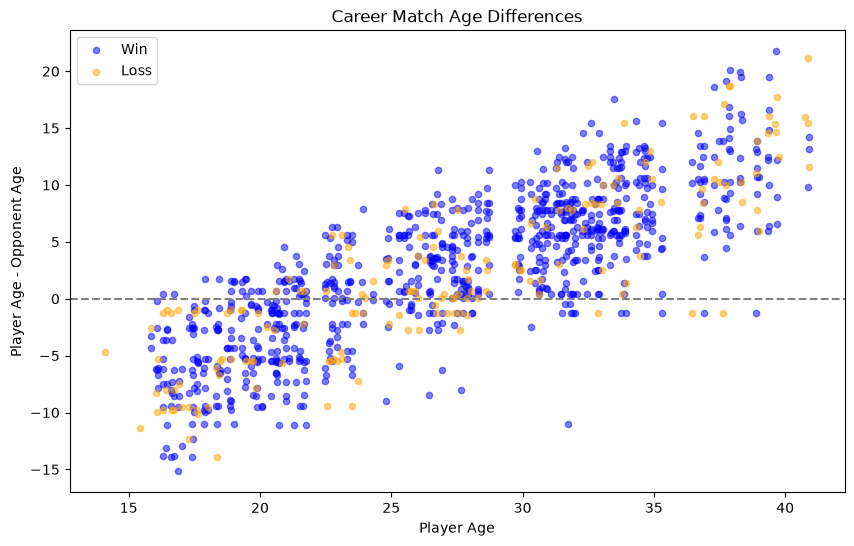

In [24]:
from tennispack.plotting import plot_player_matches

plot_player_matches(serena)

<Axes: title={'center': 'Career Match Age Differences'}, xlabel='Player Age', ylabel='Player Age - Opponent Age'>

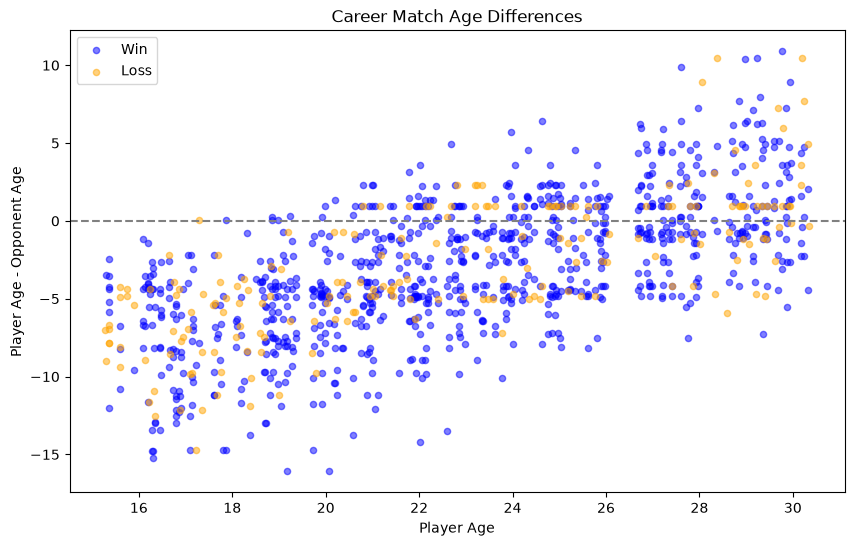

In [25]:
plot_player_matches(rafa)

<Axes: title={'center': 'Career Match Age Differences'}, xlabel='Player Age', ylabel='Player Age - Opponent Age'>

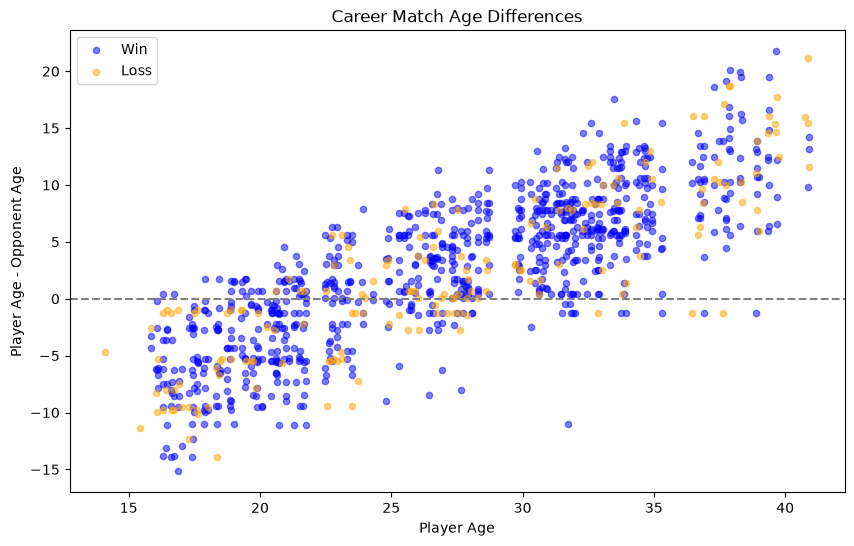

In [1]:
from tennispack import get_player_data, plot_player_matches

serena = get_player_data("Serena Williams")
plot_player_matches(serena)

In [2]:
import requests
import re

url = "https://www.tennisabstract.com/cgi-bin/player-classic.cgi?p=RafaelNadal"

response = requests.get(url, timeout=30)
response.raise_for_status()

html = response.text

matches = re.findall(
    r".{0,100}(?:birth|born|dob).{0,150}",
    html,
    flags=re.IGNORECASE
)

print(matches[:10])

['var dob = 19860603;', '", "Albert Portas", "Jan Hajek", "Jo Wilfried Tsonga", "Jan Lennard Struff", "Juan Ignacio Chela", "Borna Gojo", "Juan Martin Del Potro", "Diego Schwartzman", "Daniel Evans", "Filip Krajinovic", "Alexander Waske", "Sam Querrey", "Dustin Brown", "Marcos D', 'Israel Matos Gil", "Donald Young", "Go Soeda", "Denis Gremelmayr", "Arnaud Clement", "Jiri Vanek", "Borna Coric", "Peter Gojowczyk", "Guillermo Platel", "Jared Donaldson", "Adrian Voinea", "Kei Nishikori", "Robin Haase", "Tomas Berdych", "Thierry Ascione', 'uerdo", "John Isner", "Yannick Maden", "Mounir El Aarej", "Ivan Navarro", "Timo Nieminen", "Jordane Doble", "Tommy Paul", "Robert Farah", "Peter Luczak", "Santiago Giraldo", "Tallon Griekspoor", "Michal Tabara", "Jordan Thompson", "John Millman", "Paul ', '  ["20220815", "Cincinnati Masters", "Hard", "M", "L", "3", "2", "", "R32", "7-6(9) 4-6 6-3", "3", "Borna Coric", "152", "", "PR", "R", "19961114", "188", "CRO", "0", "171", "6", "7", "91", "50", "42", 

In [3]:
import importlib
import tennispack.data

importlib.reload(tennispack.data)

from tennispack.data import get_player_data

for name in ["Serena Williams", "Rafael Nadal", "Iga Swiatek"]:
    try:
        data = get_player_data(name)
        print(name, data.shape)
        display(data.head(3))
    except ValueError as error:
        print(name, error)

Serena Williams (1038, 6)


,date,result,opponent,opponent_age,player_age,age_difference
0,1995-10-30,L,Anne Miller,19770119,6.477755,-1.977011e+07
1,1997-03-07,L,Alexia Dechaume Balleret,19700503,7.830253,-1.970050e+07
2,1997-08-04,L,Magui Serna,19790301,8.240931,-1.979029e+07


Rafael Nadal (1096, 6)


,date,result,opponent,opponent_age,player_age,age_difference
0,2001-09-10,L,Guillermo Platel,22.264203,15.271732,-6.992471
1,2001-09-17,L,Stefano Galvani,24.290212,15.290897,-8.999316
2,2001-09-17,W,Israel Matos Gil,18.759754,15.290897,-3.468857


Iga Swiatek Could not find player profile for 'IgaSwiatek'.


,date,result,opponent,opponent_age,player_age,age_difference
0,1995-10-30,L,Anne Miller,18.776181,6.477755,-12.298426
1,1997-03-07,L,Alexia Dechaume Balleret,26.844627,7.830253,-19.014374
2,1997-08-04,L,Magui Serna,18.428474,8.240931,-10.187543
3,1997-08-04,W,Amanda Basica,19.123888,8.240931,-10.882957
4,1997-08-04,W,Tamarine Tanasugarn,20.197125,8.240931,-11.956194


,date,result,opponent,opponent_age,player_age,age_difference
0,2001-09-10,L,Guillermo Platel,22.264203,15.271732,-6.992471
1,2001-09-17,L,Stefano Galvani,24.290212,15.290897,-8.999316
2,2001-09-17,W,Israel Matos Gil,18.759754,15.290897,-3.468857
3,2001-10-15,L,Juan Giner,23.216975,15.367556,-7.849418
4,2001-10-15,W,Jordi Marse Vidri,21.234771,15.367556,-5.867214


,date,result,opponent,opponent_age,player_age,age_difference
0,2016-10-24,W,Laura Ioana Andrei,28.399726,27.463381,-0.936345
1,2016-10-24,W,Karen Barbat,24.309377,27.463381,3.154004
2,2016-10-24,W,Andrea Ka,24.495551,27.463381,2.96783
3,2016-10-24,W,Anna Klasen,22.940452,27.463381,4.52293
4,2016-10-24,W,Julie Gervais,25.259411,27.463381,2.20397


<Axes: title={'center': 'Career Match Age Differences'}, xlabel='Player Age', ylabel='Player Age - Opponent Age'>

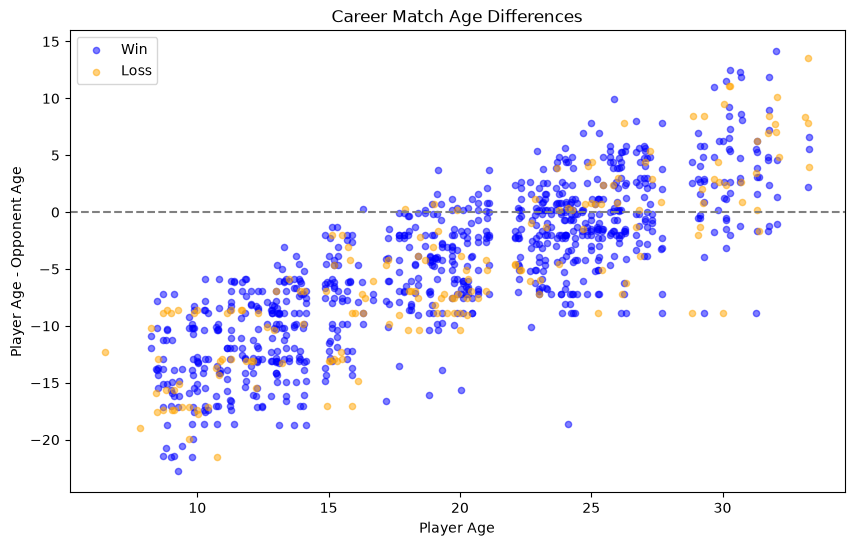

In [1]:
from tennispack import get_player_data, plot_player_matches

serena = get_player_data("Serena Williams")
rafa = get_player_data("Rafael Nadal")
iga = get_player_data("Iga Swiatek")

display(serena.head())
display(rafa.head())
display(iga.head())

plot_player_matches(serena)

In [1]:
import importlib
import tennispack.data

importlib.reload(tennispack.data)

from tennispack.data import get_player_data, _get_player_dob

print("Serena DOB:", _get_player_dob("SerenaWilliams"))
print("Nadal DOB:", _get_player_dob("RafaelNadal"))

serena = get_player_data("Serena Williams")
display(serena.head())

Serena DOB: 19810926


Nadal DOB: 19860603


,date,result,opponent,opponent_age,player_age,age_difference
0,1995-10-30,L,Anne Miller,18.776181,14.091718,-4.684463
1,1997-03-07,L,Alexia Dechaume Balleret,26.844627,15.444216,-11.400411
2,1997-08-04,L,Magui Serna,18.428474,15.854894,-2.57358
3,1997-08-04,W,Amanda Basica,19.123888,15.854894,-3.268994
4,1997-08-04,W,Tamarine Tanasugarn,20.197125,15.854894,-4.342231


In [2]:
iga = get_player_data("Iga Swiatek")
display(iga.head())

,date,result,opponent,opponent_age,player_age,age_difference
0,2016-10-24,W,Laura Ioana Andrei,28.399726,15.400411,-12.999316
1,2016-10-24,W,Karen Barbat,24.309377,15.400411,-8.908966
2,2016-10-24,W,Andrea Ka,24.495551,15.400411,-9.09514
3,2016-10-24,W,Anna Klasen,22.940452,15.400411,-7.540041
4,2016-10-24,W,Julie Gervais,25.259411,15.400411,-9.859001
